In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/home/jovyan/work")
AE_PATH = PROJECT_ROOT / "data" / "raw" / "ae"

In [2]:
file_path = AE_PATH / "Monthly-AE-April-2024-revised.csv"

ae = pd.read_csv(file_path)

print(ae.shape)
ae.head()

(198, 22)


,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-APRIL-2024,AAH,NHS ENGLAND SOUTH WEST,TETBURY HOSPITAL TRUST LTD,0,0,546,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-APRIL-2024,RAN,NHS ENGLAND LONDON,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,41
2,MSitAE-APRIL-2024,8J094,NHS ENGLAND MIDLANDS,BADGER LTD,0,0,0,0,0,2078,...,0,0,0,0,0,0,0,0,0,0
3,MSitAE-APRIL-2024,AD913,NHS ENGLAND LONDON,BECKENHAM BEACON UCC,0,0,3694,0,0,104,...,17,0,0,0,0,0,0,0,0,0
4,MSitAE-APRIL-2024,AQN04,NHS ENGLAND SOUTH EAST,PHL LYMINGTON UTC,0,0,2897,0,0,7,...,8,0,0,0,0,0,0,0,0,0


In [3]:
ae.info()

<class 'pandas.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 22 columns):
 #   Column                                                      Non-Null Count  Dtype
---  ------                                                      --------------  -----
 0   Period                                                      198 non-null    str  
 1   Org Code                                                    198 non-null    str  
 2   Parent Org                                                  198 non-null    str  
 3   Org name                                                    198 non-null    str  
 4   A&E attendances Type 1                                      198 non-null    int64
 5   A&E attendances Type 2                                      198 non-null    int64
 6   A&E attendances Other A&E Department                        198 non-null    int64
 7   A&E attendances Booked Appointments Type 1                  198 non-null    int64
 8   A&E attendances Booked Appointm

In [4]:
ae.columns.tolist()

['Period',
 'Org Code',
 'Parent Org',
 'Org name',
 'A&E attendances Type 1',
 'A&E attendances Type 2',
 'A&E attendances Other A&E Department',
 'A&E attendances Booked Appointments Type 1',
 'A&E attendances Booked Appointments Type 2',
 'A&E attendances Booked Appointments Other Department',
 'Attendances over 4hrs Type 1',
 'Attendances over 4hrs Type 2',
 'Attendances over 4hrs Other Department',
 'Attendances over 4hrs Booked Appointments Type 1',
 'Attendances over 4hrs Booked Appointments Type 2',
 'Attendances over 4hrs Booked Appointments Other Department',
 'Patients who have waited 4-12 hs from DTA to admission',
 'Patients who have waited 12+ hrs from DTA to admission',
 'Emergency admissions via A&E - Type 1',
 'Emergency admissions via A&E - Type 2',
 'Emergency admissions via A&E - Other A&E department',
 'Other emergency admissions']

In [5]:
print("Duplicate rows:", ae.duplicated().sum())

Duplicate rows: 0


In [6]:
ae.isnull().sum()

Period                                                        0
Org Code                                                      0
Parent Org                                                    0
Org name                                                      0
A&E attendances Type 1                                        0
A&E attendances Type 2                                        0
A&E attendances Other A&E Department                          0
A&E attendances Booked Appointments Type 1                    0
A&E attendances Booked Appointments Type 2                    0
A&E attendances Booked Appointments Other Department          0
Attendances over 4hrs Type 1                                  0
Attendances over 4hrs Type 2                                  0
Attendances over 4hrs Other Department                        0
Attendances over 4hrs Booked Appointments Type 1              0
Attendances over 4hrs Booked Appointments Type 2              0
Attendances over 4hrs Booked Appointment

In [7]:
print("Shape:", ae.shape)
print("Unique organisations:", ae["Org Code"].nunique())
print("Period values:", ae["Period"].unique())

Shape: (198, 22)
Unique organisations: 198
Period values: <ArrowStringArray>
['MSitAE-APRIL-2024', 'Total ']
Length: 2, dtype: str


In [8]:
ae["Period"].value_counts(dropna=False)

Period
MSitAE-APRIL-2024    197
Total                  1
Name: count, dtype: int64

In [9]:
ae[ae["Period"].str.strip() == "Total"]

,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
197,Total,Total,Total,Total,1341059,50804,771286,30969,691,45859,...,26223,7976,12,629,92266,42078,398116,1442,4376,140179


In [10]:
ae_org = ae[ae["Period"].str.strip() != "Total"].copy()

print("Organisation rows:", ae_org.shape[0])
print("Unique organisations:", ae_org["Org Code"].nunique())

Organisation rows: 197
Unique organisations: 197


In [12]:
# Store the three main A&E attendance columns in a list
attendance_cols = [
    "A&E attendances Type 1",
    "A&E attendances Type 2",
    "A&E attendances Other A&E Department"
]

In [13]:
# Check whether the attendance columns are stored as numbers
ae_org[attendance_cols].dtypes

A&E attendances Type 1                  int64
A&E attendances Type 2                  int64
A&E attendances Other A&E Department    int64
dtype: object

In [14]:
# Create a new column by adding the three attendance types
ae_org["Total A&E Attendances"] = (
    ae_org["A&E attendances Type 1"]
    + ae_org["A&E attendances Type 2"]
    + ae_org["A&E attendances Other A&E Department"]
)

# Show organisation name and calculated total
ae_org[["Org name", "Total A&E Attendances"]].head()

,Org name,Total A&E Attendances
0,TETBURY HOSPITAL TRUST LTD,546
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0
2,BADGER LTD,0
3,BECKENHAM BEACON UCC,3694
4,PHL LYMINGTON UTC,2897


In [15]:
# Find the 10 organisations with the highest A&E attendances
top_10 = ae_org.sort_values(
    "Total A&E Attendances",
    ascending=False
).head(10)

# Show organisation name and total attendances
top_10[["Org name", "Total A&E Attendances"]]

,Org name,Total A&E Attendances
96,BARTS HEALTH NHS TRUST,41185
181,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,38288
98,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,34741
82,FRIMLEY HEALTH NHS FOUNDATION TRUST,34702
87,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,34521
193,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,33444
88,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,30582
149,LEEDS TEACHING HOSPITALS NHS TRUST,29474
167,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",28426
122,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,27762


In [16]:
# Store the three main "over 4 hours" columns in a list
over_4h_cols = [
    "Attendances over 4hrs Type 1",
    "Attendances over 4hrs Type 2",
    "Attendances over 4hrs Other Department"
]

# Check the data types
ae_org[over_4h_cols].dtypes

Attendances over 4hrs Type 1              int64
Attendances over 4hrs Type 2              int64
Attendances over 4hrs Other Department    int64
dtype: object

In [17]:
# Create a new column for total patients waiting over 4 hours
ae_org["Total Over 4 Hours"] = (
    ae_org["Attendances over 4hrs Type 1"]
    + ae_org["Attendances over 4hrs Type 2"]
    + ae_org["Attendances over 4hrs Other Department"]
)

# Show organisation name, total attendances, and patients waiting over 4 hours
ae_org[
    ["Org name", "Total A&E Attendances", "Total Over 4 Hours"]
].head()

,Org name,Total A&E Attendances,Total Over 4 Hours
0,TETBURY HOSPITAL TRUST LTD,546,0
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0
2,BADGER LTD,0,0
3,BECKENHAM BEACON UCC,3694,17
4,PHL LYMINGTON UTC,2897,8


In [18]:
# Calculate the percentage of patients who waited over 4 hours
ae_org["4 Hour Breach Rate %"] = (
    ae_org["Total Over 4 Hours"]
    / ae_org["Total A&E Attendances"]
    * 100
)

# Show the result
ae_org[
    [
        "Org name",
        "Total A&E Attendances",
        "Total Over 4 Hours",
        "4 Hour Breach Rate %"
    ]
].head()

,Org name,Total A&E Attendances,Total Over 4 Hours,4 Hour Breach Rate %
0,TETBURY HOSPITAL TRUST LTD,546,0,0.000000
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,NaN
2,BADGER LTD,0,0,NaN
3,BECKENHAM BEACON UCC,3694,17,0.460206
4,PHL LYMINGTON UTC,2897,8,0.276148


In [19]:
# Round the breach rate to 2 decimal places
ae_org["4 Hour Breach Rate %"] = ae_org["4 Hour Breach Rate %"].round(2)

# Show the first 5 rows
ae_org[
    ["Org name", "Total A&E Attendances", "Total Over 4 Hours", "4 Hour Breach Rate %"]
].head()

,Org name,Total A&E Attendances,Total Over 4 Hours,4 Hour Breach Rate %
0,TETBURY HOSPITAL TRUST LTD,546,0,0.00
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,NaN
2,BADGER LTD,0,0,NaN
3,BECKENHAM BEACON UCC,3694,17,0.46
4,PHL LYMINGTON UTC,2897,8,0.28


In [20]:
# Calculate the percentage of patients handled within 4 hours
ae_org["4 Hour Performance %"] = 100 - ae_org["4 Hour Breach Rate %"]

# Show the result
ae_org[
    ["Org name", "4 Hour Breach Rate %", "4 Hour Performance %"]
].head()

,Org name,4 Hour Breach Rate %,4 Hour Performance %
0,TETBURY HOSPITAL TRUST LTD,0.00,100.00
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,NaN,NaN
2,BADGER LTD,NaN,NaN
3,BECKENHAM BEACON UCC,0.46,99.54
4,PHL LYMINGTON UTC,0.28,99.72


In [21]:
# Select the 10 busiest A&E organisations
top_10_busy = ae_org.sort_values(
    "Total A&E Attendances",
    ascending=False
).head(10)

# Show their activity and 4-hour performance
top_10_busy[
    [
        "Org name",
        "Total A&E Attendances",
        "Total Over 4 Hours",
        "4 Hour Performance %"
    ]
]

,Org name,Total A&E Attendances,Total Over 4 Hours,4 Hour Performance %
96,BARTS HEALTH NHS TRUST,41185,14233,65.44
181,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,38288,11898,68.92
98,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,34741,8092,76.71
82,FRIMLEY HEALTH NHS FOUNDATION TRUST,34702,8873,74.43
87,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,34521,13841,59.91
193,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,33444,10453,68.74
88,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,30582,8292,72.89
149,LEEDS TEACHING HOSPITALS NHS TRUST,29474,6657,77.41
167,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",28426,6213,78.14
122,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,27762,10147,63.45


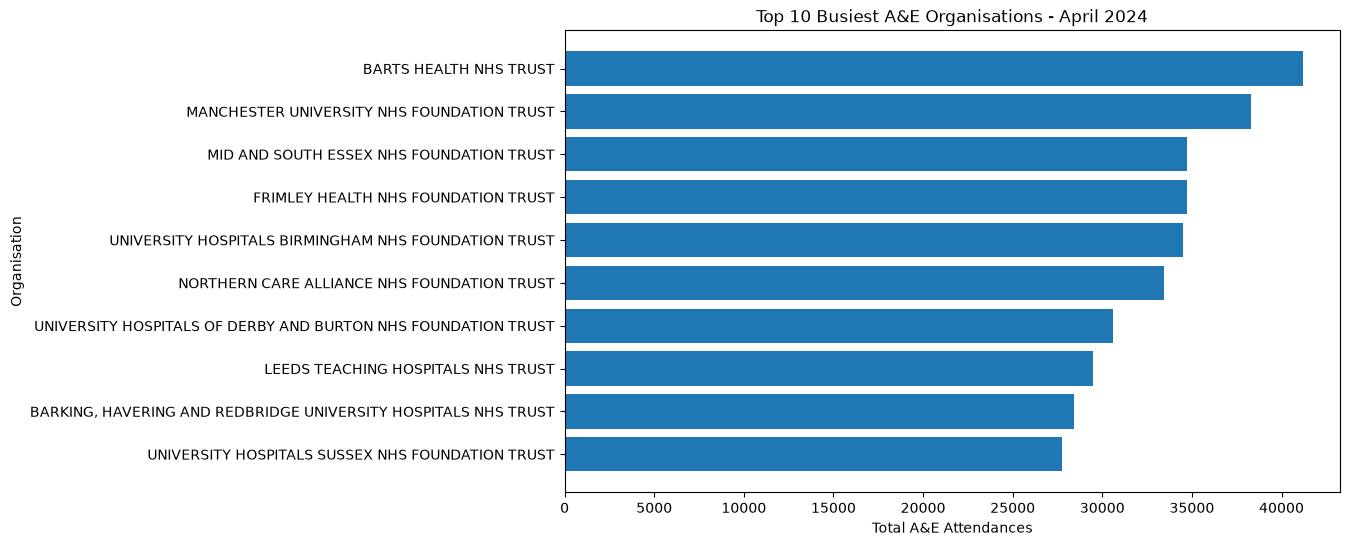

In [22]:
import matplotlib.pyplot as plt

# Sort top 10 organisations from lowest to highest
chart_data = top_10_busy.sort_values("Total A&E Attendances")

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    chart_data["Org name"],
    chart_data["Total A&E Attendances"]
)

plt.title("Top 10 Busiest A&E Organisations - April 2024")
plt.xlabel("Total A&E Attendances")
plt.ylabel("Organisation")

plt.show()

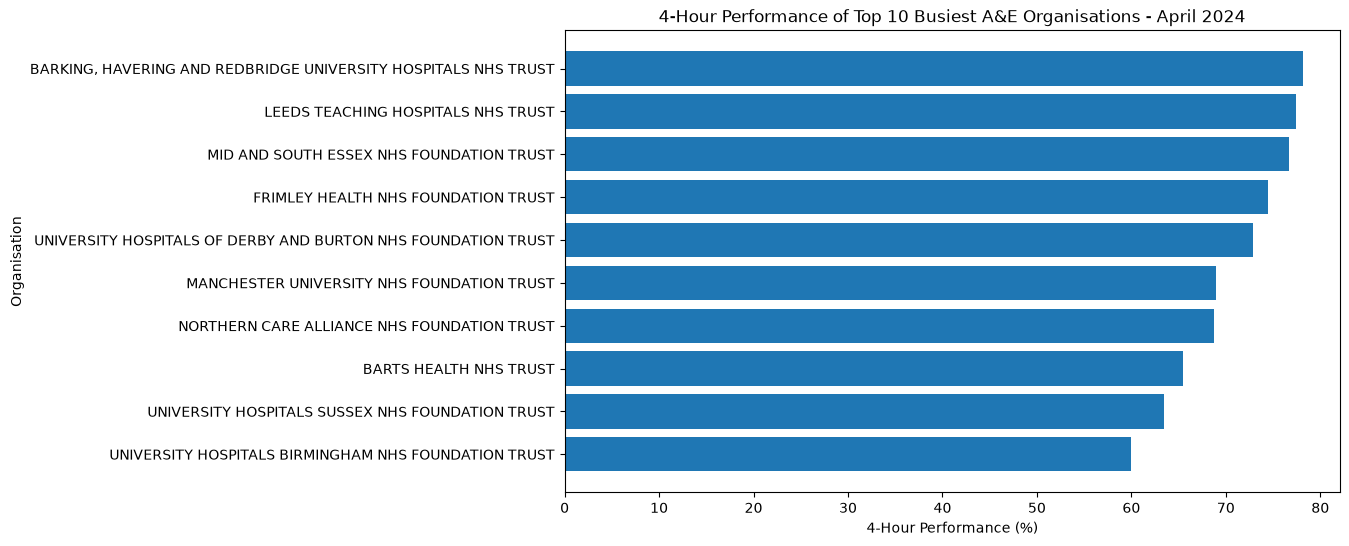

In [23]:
# Sort the same top 10 organisations by 4-hour performance
performance_data = top_10_busy.sort_values("4 Hour Performance %")

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    performance_data["Org name"],
    performance_data["4 Hour Performance %"]
)

plt.title("4-Hour Performance of Top 10 Busiest A&E Organisations - April 2024")
plt.xlabel("4-Hour Performance (%)")
plt.ylabel("Organisation")

plt.show()

## Key Insight

Among the 10 busiest A&E organisations in April 2024, activity levels varied alongside 4-hour performance.

Barts Health NHS Trust recorded the highest number of A&E attendances at 41,185, with a 4-hour performance of 65.44%.

University Hospitals Birmingham NHS Foundation Trust had one of the weakest performance levels among the busiest organisations, at 59.91%.

In comparison, Barking, Havering and Redbridge University Hospitals achieved a higher 4-hour performance of 78.14% despite also handling a high volume of attendances.

This suggests that high demand may be associated with operational pressure, but a single month is not enough to establish a clear relationship. Further analysis across multiple months is required.


In [24]:
# Store emergency admission columns in a list
admission_cols = [
    "Emergency admissions via A&E - Type 1",
    "Emergency admissions via A&E - Type 2",
    "Emergency admissions via A&E - Other A&E department",
    "Other emergency admissions"
]

# Check whether these columns are numeric
ae_org[admission_cols].dtypes

Emergency admissions via A&E - Type 1                  int64
Emergency admissions via A&E - Type 2                  int64
Emergency admissions via A&E - Other A&E department    int64
Other emergency admissions                             int64
dtype: object

In [25]:
# Create a new column for total emergency admissions
ae_org["Total Emergency Admissions"] = (
    ae_org["Emergency admissions via A&E - Type 1"]
    + ae_org["Emergency admissions via A&E - Type 2"]
    + ae_org["Emergency admissions via A&E - Other A&E department"]
    + ae_org["Other emergency admissions"]
)

# Show the first 5 rows
ae_org[
    ["Org name", "Total A&E Attendances", "Total Emergency Admissions"]
].head()

,Org name,Total A&E Attendances,Total Emergency Admissions
0,TETBURY HOSPITAL TRUST LTD,546,0
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,41
2,BADGER LTD,0,0
3,BECKENHAM BEACON UCC,3694,0
4,PHL LYMINGTON UTC,2897,0


In [26]:
# Calculate admissions that happened specifically through A&E
ae_org["Admissions via A&E"] = (
    ae_org["Emergency admissions via A&E - Type 1"]
    + ae_org["Emergency admissions via A&E - Type 2"]
    + ae_org["Emergency admissions via A&E - Other A&E department"]
)

# Show the difference between A&E admissions and other emergency admissions
ae_org[
    [
        "Org name",
        "Total A&E Attendances",
        "Admissions via A&E",
        "Other emergency admissions"
    ]
].head()

,Org name,Total A&E Attendances,Admissions via A&E,Other emergency admissions
0,TETBURY HOSPITAL TRUST LTD,546,0,0
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,41
2,BADGER LTD,0,0,0
3,BECKENHAM BEACON UCC,3694,0,0
4,PHL LYMINGTON UTC,2897,0,0


In [27]:
# Calculate the percentage of A&E attendances that resulted in admission
ae_org["A&E Admission Rate %"] = (
    ae_org["Admissions via A&E"]
    / ae_org["Total A&E Attendances"]
    * 100
)

# Round the result to 2 decimal places
ae_org["A&E Admission Rate %"] = ae_org["A&E Admission Rate %"].round(2)

# Show the first 5 rows
ae_org[
    [
        "Org name",
        "Total A&E Attendances",
        "Admissions via A&E",
        "A&E Admission Rate %"
    ]
].head()

,Org name,Total A&E Attendances,Admissions via A&E,A&E Admission Rate %
0,TETBURY HOSPITAL TRUST LTD,546,0,0.0
1,ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST,0,0,NaN
2,BADGER LTD,0,0,NaN
3,BECKENHAM BEACON UCC,3694,0,0.0
4,PHL LYMINGTON UTC,2897,0,0.0


In [28]:
# Keep only organisations that had at least one A&E attendance
ae_with_activity = ae_org[
    ae_org["Total A&E Attendances"] > 0
].copy()

# Sort organisations by admission rate from highest to lowest
top_admission_rate = ae_with_activity.sort_values(
    "A&E Admission Rate %",
    ascending=False
).head(10)

# Show the top 10
top_admission_rate[
    [
        "Org name",
        "Total A&E Attendances",
        "Admissions via A&E",
        "A&E Admission Rate %"
    ]
]

,Org name,Total A&E Attendances,Admissions via A&E,A&E Admission Rate %
101,DORSET COUNTY HOSPITAL NHS FOUNDATION TRUST,4182,1866,44.62
45,THE ROTHERHAM NHS FOUNDATION TRUST,8172,2978,36.44
133,CHESTERFIELD ROYAL HOSPITAL NHS FOUNDATION TRUST,8282,2985,36.04
26,BARNSLEY HOSPITAL NHS FOUNDATION TRUST,8335,2872,34.46
110,HAMPSHIRE HOSPITALS NHS FOUNDATION TRUST,12734,4284,33.64
114,ASHFORD AND ST PETER'S HOSPITALS NHS FOUNDATIO...,9838,3140,31.92
89,NORTH BRISTOL NHS TRUST,8952,2825,31.56
97,ROYAL SURREY COUNTY HOSPITAL NHS FOUNDATION TRUST,7899,2491,31.54
11,BUCKINGHAMSHIRE HEALTHCARE NHS TRUST,14500,4565,31.48
188,NORTHERN LINCOLNSHIRE AND GOOLE NHS FOUNDATION...,15524,4816,31.02


In [29]:
# Create a simple summary of April 2024
april_summary = {
    "Total Organisations": len(ae_org),
    "Total A&E Attendances": ae_org["Total A&E Attendances"].sum(),
    "Total Over 4 Hours": ae_org["Total Over 4 Hours"].sum(),
    "Total Admissions via A&E": ae_org["Admissions via A&E"].sum()
}

april_summary

{'Total Organisations': 197,
 'Total A&E Attendances': np.int64(2163149),
 'Total Over 4 Hours': np.int64(563068),
 'Total Admissions via A&E': np.int64(403934)}

In [30]:
# Get the official Total row from the original dataset
total_row = ae[ae["Period"].str.strip() == "Total"].iloc[0]

In [31]:
# Calculate total attendances from the official NHS Total row
official_attendances = total_row[attendance_cols].sum()

print("Our calculated total:", ae_org["Total A&E Attendances"].sum())
print("Official NHS total:", official_attendances)

Our calculated total: 2163149
Official NHS total: 2163149


In [32]:
# Calculate total over-4-hour waits from the official NHS Total row
official_over_4h = total_row[over_4h_cols].sum()

print("Our calculated total:", ae_org["Total Over 4 Hours"].sum())
print("Official NHS total:", official_over_4h)

Our calculated total: 563068
Official NHS total: 563068


In [33]:
# Create a reusable function to process one A&E monthly file
def process_ae_file(file_path):

    # Load the CSV file
    df = pd.read_csv(file_path)

    # Remove the overall Total row
    df_org = df[df["Period"].str.strip() != "Total"].copy()

    # Calculate total A&E attendances
    df_org["Total A&E Attendances"] = (
        df_org["A&E attendances Type 1"]
        + df_org["A&E attendances Type 2"]
        + df_org["A&E attendances Other A&E Department"]
    )

    # Calculate total patients waiting over 4 hours
    df_org["Total Over 4 Hours"] = (
        df_org["Attendances over 4hrs Type 1"]
        + df_org["Attendances over 4hrs Type 2"]
        + df_org["Attendances over 4hrs Other Department"]
    )

    # Calculate admissions that happened through A&E
    df_org["Admissions via A&E"] = (
        df_org["Emergency admissions via A&E - Type 1"]
        + df_org["Emergency admissions via A&E - Type 2"]
        + df_org["Emergency admissions via A&E - Other A&E department"]
    )

    # Create a small monthly summary
    summary = {
        "Attendances": df_org["Total A&E Attendances"].sum(),
        "Over 4 Hours": df_org["Total Over 4 Hours"].sum(),
        "Admissions via A&E": df_org["Admissions via A&E"].sum()
    }

    return summary

In [34]:
# Path to the May 2024 A&E file
may_file = AE_PATH / "Monthly-AE-May-2024.csv"

# Process May using our function
may_summary = process_ae_file(may_file)

may_summary

{'Attendances': np.int64(4662020),
 'Over 4 Hours': np.int64(1238570),
 'Admissions via A&E': np.int64(840408)}

In [35]:
# Load the May 2024 A&E file
may_df = pd.read_csv(
    AE_PATH / "Monthly-AE-May-2024.csv"
)

# Show the size of the dataset
print("Shape:", may_df.shape)

Shape: (198, 22)


In [36]:
# Check the values inside the Period column
may_df["Period"].value_counts(dropna=False)

Period
MSitAE-MAY-2024    197
TOTAL                1
Name: count, dtype: int64

In [37]:
# Check whether any rows are duplicated
print("Duplicate rows:", may_df.duplicated().sum())

Duplicate rows: 0


In [38]:
# Count unique organisation codes
print("Unique organisations:", may_df["Org Code"].nunique())

Unique organisations: 198


In [39]:
# Show the TOTAL row to inspect its organisation fields
may_df[may_df["Period"].str.strip().str.upper() == "TOTAL"][
    ["Period", "Org Code", "Org name"]
]

,Period,Org Code,Org name
197,TOTAL,TOTAL,TOTAL


In [42]:
# Remove the TOTAL row from the May dataset
may_org = may_df[
    may_df["Period"].str.strip().str.upper() != "TOTAL"
].copy()

# Check how many organisation rows are left
print("Organisation rows:", len(may_org))

Organisation rows: 197


In [43]:
# Calculate total A&E attendances for each organisation
may_org["Total A&E Attendances"] = (
    may_org["A&E attendances Type 1"]
    + may_org["A&E attendances Type 2"]
    + may_org["A&E attendances Other A&E Department"]
)

# Add all organisation attendances together
may_total = may_org["Total A&E Attendances"].sum()

print("May 2024 A&E Attendances:", may_total)

May 2024 A&E Attendances: 2331010


In [45]:
# Calculate total A&E attendances for April 2024
april_total = ae_org["Total A&E Attendances"].sum()

print("April 2024:", april_total)

April 2024: 2163149


In [46]:
# Calculate the increase in attendances from April to May
increase = may_total - april_total

print("Increase:", increase)

Increase: 167861


In [47]:
# Calculate the percentage increase from April to May
growth_rate = (increase / april_total) * 100

print("Growth rate:", round(growth_rate, 2), "%")

Growth rate: 7.76 %


In [48]:
# Process one monthly A&E file
def process_ae_file(file_path):

    # Load the CSV file
    df = pd.read_csv(file_path)

    # Remove the overall TOTAL row
    # .str.upper() makes "Total", "TOTAL", "total" all the same
    df_org = df[
        df["Period"].str.strip().str.upper() != "TOTAL"
    ].copy()

    # Calculate total A&E attendances
    df_org["Total A&E Attendances"] = (
        df_org["A&E attendances Type 1"]
        + df_org["A&E attendances Type 2"]
        + df_org["A&E attendances Other A&E Department"]
    )

    # Calculate patients waiting over 4 hours
    df_org["Total Over 4 Hours"] = (
        df_org["Attendances over 4hrs Type 1"]
        + df_org["Attendances over 4hrs Type 2"]
        + df_org["Attendances over 4hrs Other Department"]
    )

    # Calculate admissions through A&E
    df_org["Admissions via A&E"] = (
        df_org["Emergency admissions via A&E - Type 1"]
        + df_org["Emergency admissions via A&E - Type 2"]
        + df_org["Emergency admissions via A&E - Other A&E department"]
    )

    # Calculate monthly totals
    attendances = df_org["Total A&E Attendances"].sum()
    over_4h = df_org["Total Over 4 Hours"].sum()
    admissions = df_org["Admissions via A&E"].sum()

    # Calculate 4-hour performance
    performance = ((attendances - over_4h) / attendances) * 100

    # Return the monthly results
    return {
        "Attendances": attendances,
        "Over 4 Hours": over_4h,
        "4 Hour Performance %": round(performance, 2),
        "Admissions via A&E": admissions
    }

In [49]:
# April 2024
april_result = process_ae_file(
    AE_PATH / "Monthly-AE-April-2024-revised.csv"
)

april_result

{'Attendances': np.int64(2163149),
 'Over 4 Hours': np.int64(563068),
 '4 Hour Performance %': np.float64(73.97),
 'Admissions via A&E': np.int64(403934)}

In [50]:
# May 2024
may_result = process_ae_file(
    AE_PATH / "Monthly-AE-May-2024.csv"
)

may_result

{'Attendances': np.int64(2331010),
 'Over 4 Hours': np.int64(619285),
 '4 Hour Performance %': np.float64(73.43),
 'Admissions via A&E': np.int64(420204)}

In [51]:
# Process April 2024 using the same function
april_result = process_ae_file(
    AE_PATH / "Monthly-AE-April-2024-revised.csv"
)

april_result

{'Attendances': np.int64(2163149),
 'Over 4 Hours': np.int64(563068),
 '4 Hour Performance %': np.float64(73.97),
 'Admissions via A&E': np.int64(403934)}

In [52]:
# Get all A&E CSV files
ae_files = sorted(AE_PATH.glob("*.csv"))

# Create an empty list to store monthly results
monthly_results = []

# Process each file one by one
for file in ae_files:

    # Run our reusable function
    result = process_ae_file(file)

    # Store the file name as well
    result["File Name"] = file.name

    # Add the result to the list
    monthly_results.append(result)

# Convert the list into a DataFrame
monthly_df = pd.DataFrame(monthly_results)

# Show the first few rows
monthly_df.head()

,Attendances,Over 4 Hours,4 Hour Performance %,Admissions via A&E,File Name
0,2209687,571127,74.15,396292,April-2025-CSV-revised.csv
1,2271552,534592,76.47,392805,April-2026-CSV-QD21vf.csv
2,2182723,539040,75.30,400920,August-2025-CSV-revised.csv
3,2265327,576553,74.55,392869,August-2026-CSV-De2k3n.csv
4,4087144,1083270,73.50,723860,February-2026-CSV-Dl8t54.csv


In [53]:
# Load the February 2026 file
feb_df = pd.read_csv(
    AE_PATH / "February-2026-CSV-Dl8t54.csv"
)

# Check the size of the file
print("Shape:", feb_df.shape)

# Check the different Period values
print(feb_df["Period"].value_counts(dropna=False))

Shape: (198, 22)
Period
MSitAE-FEBRUARY-2026    198
Name: count, dtype: int64


In [54]:
# Check how many unique organisation codes exist
print("Unique organisations:", feb_df["Org Code"].nunique())

Unique organisations: 198


In [55]:
# Look for any row where organisation code or name contains TOTAL
feb_df[
    feb_df["Org Code"].astype(str).str.contains("TOTAL", case=False, na=False)
    |
    feb_df["Org name"].astype(str).str.contains("TOTAL", case=False, na=False)
][
    ["Period", "Org Code", "Org name"]
]

,Period,Org Code,Org name
197,MSitAE-FEBRUARY-2026,TOTAL,TOTAL


In [58]:
# Process one monthly A&E file
def process_ae_file(file_path):

    # Load the CSV file
    df = pd.read_csv(file_path)

    # Remove the overall TOTAL row
    # Different NHS files may mark TOTAL in different columns
    df_org = df[
        (df["Period"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org Code"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org name"].astype(str).str.strip().str.upper() != "TOTAL")
    ].copy()

    # Calculate total A&E attendances
    df_org["Total A&E Attendances"] = (
        df_org["A&E attendances Type 1"]
        + df_org["A&E attendances Type 2"]
        + df_org["A&E attendances Other A&E Department"]
    )

    # Calculate patients waiting over 4 hours
    df_org["Total Over 4 Hours"] = (
        df_org["Attendances over 4hrs Type 1"]
        + df_org["Attendances over 4hrs Type 2"]
        + df_org["Attendances over 4hrs Other Department"]
    )

    # Calculate admissions through A&E
    df_org["Admissions via A&E"] = (
        df_org["Emergency admissions via A&E - Type 1"]
        + df_org["Emergency admissions via A&E - Type 2"]
        + df_org["Emergency admissions via A&E - Other A&E department"]
    )

    # Calculate monthly totals
    attendances = df_org["Total A&E Attendances"].sum()
    over_4h = df_org["Total Over 4 Hours"].sum()
    admissions = df_org["Admissions via A&E"].sum()

    # Calculate 4-hour performance
    performance = ((attendances - over_4h) / attendances) * 100

    # Return the monthly summary
    return {
        "Attendances": attendances,
        "Over 4 Hours": over_4h,
        "4 Hour Performance %": round(performance, 2),
        "Admissions via A&E": admissions
    }

In [59]:
# Test the corrected function on February 2026
feb_result = process_ae_file(
    AE_PATH / "February-2026-CSV-Dl8t54.csv"
)

feb_result

{'Attendances': np.int64(2043572),
 'Over 4 Hours': np.int64(541635),
 '4 Hour Performance %': np.float64(73.5),
 'Admissions via A&E': np.int64(361930)}

In [60]:
# Get all A&E CSV files
ae_files = sorted(AE_PATH.glob("*.csv"))

# Store results here
monthly_results = []

# Process every monthly file
for file in ae_files:

    result = process_ae_file(file)

    # Keep the file name for reference
    result["File Name"] = file.name

    monthly_results.append(result)

# Convert results into a DataFrame
monthly_df = pd.DataFrame(monthly_results)

monthly_df.head(10)

,Attendances,Over 4 Hours,4 Hour Performance %,Admissions via A&E,File Name
0,2209687,571127,74.15,396292,April-2025-CSV-revised.csv
1,2271552,534592,76.47,392805,April-2026-CSV-QD21vf.csv
2,2182723,539040,75.30,400920,August-2025-CSV-revised.csv
3,2265327,576553,74.55,392869,August-2026-CSV-De2k3n.csv
4,2043572,541635,73.50,361930,February-2026-CSV-Dl8t54.csv
5,2320374,560285,75.85,419451,July-2025-CSV-revised.csv
6,2411415,604766,74.92,408030,July-2026-CSV-Trf28h.csv
7,2268166,566734,75.01,401880,June-2025-CSV-revised.csv
8,2362271,600784,74.57,397954,June-2026-CSV-Wfg38l.csv
9,2309298,581375,74.82,409526,May-2025-CSV-revised.csv


In [62]:
# Extract Month-Year from the file name
monthly_df["Month Text"] = monthly_df["File Name"].str.extract(
    r"(?i)((?:January|February|March|April|May|June|July|August|September|October|November|December)-\d{4})",
    expand=False
)

monthly_df[["File Name", "Month Text"]].head(10)

,File Name,Month Text
0,April-2025-CSV-revised.csv,April-2025
1,April-2026-CSV-QD21vf.csv,April-2026
2,August-2025-CSV-revised.csv,August-2025
3,August-2026-CSV-De2k3n.csv,August-2026
4,February-2026-CSV-Dl8t54.csv,February-2026
5,July-2025-CSV-revised.csv,July-2025
6,July-2026-CSV-Trf28h.csv,July-2026
7,June-2025-CSV-revised.csv,June-2025
8,June-2026-CSV-Wfg38l.csv,June-2026
9,May-2025-CSV-revised.csv,May-2025


In [63]:
# Check if any file name failed to produce a Month Text value
missing_months = monthly_df[
    monthly_df["Month Text"].isna()
]

print("Files with missing Month Text:", len(missing_months))

missing_months[["File Name"]]

Files with missing Month Text: 1


,File Name
23,Monthly-AE-Nov-25-CSV-revised.csv


In [64]:
# Fix the inconsistent November 2025 file name
monthly_df.loc[
    monthly_df["File Name"] == "Monthly-AE-Nov-25-CSV-revised.csv",
    "Month Text"
] = "November-2025"

In [65]:
# Check again for missing month values
print(
    "Files with missing Month Text:",
    monthly_df["Month Text"].isna().sum()
)

Files with missing Month Text: 0


In [66]:
# Convert the text month into a real date
monthly_df["Month"] = pd.to_datetime(
    monthly_df["Month Text"],
    format="%B-%Y"
)

# Sort the dataset chronologically
monthly_df = monthly_df.sort_values("Month").reset_index(drop=True)

In [67]:
monthly_df[
    [
        "Month",
        "Attendances",
        "Over 4 Hours",
        "4 Hour Performance %",
        "Admissions via A&E"
    ]
].head(10)

,Month,Attendances,Over 4 Hours,4 Hour Performance %,Admissions via A&E
0,2024-04-01,2163149,563068,73.97,403934
1,2024-05-01,2331010,619285,73.43,420204
2,2024-06-01,2215640,574514,74.07,402055
3,2024-07-01,2251330,568225,74.76,411782
4,2024-08-01,2086225,504447,75.82,396515
5,2024-09-01,2140977,563079,73.70,399406
6,2024-10-01,2280392,626992,72.51,422048
7,2024-11-01,2234578,634410,71.61,414109
8,2024-12-01,2258452,667235,70.46,417067
9,2025-01-01,2133300,589826,72.35,406228


In [68]:
# Check number of rows and unique months
print("Total rows:", len(monthly_df))
print("Unique months:", monthly_df["Month"].nunique())

# Check the date range
print("First month:", monthly_df["Month"].min())
print("Last month:", monthly_df["Month"].max())

Total rows: 29
Unique months: 29
First month: 2024-04-01 00:00:00
Last month: 2026-08-01 00:00:00


In [69]:
# Create the full expected monthly date range
expected_months = pd.date_range(
    start=monthly_df["Month"].min(),
    end=monthly_df["Month"].max(),
    freq="MS"
)

# Find any missing months
missing_months = expected_months.difference(monthly_df["Month"])

print("Missing months:", missing_months)

Missing months: DatetimeIndex([], dtype='datetime64[us]', freq='MS')


In [70]:
# Check total number of rows and unique months
print("Total rows:", len(monthly_df))
print("Unique months:", monthly_df["Month"].nunique())

# Check first and last month
print("First month:", monthly_df["Month"].min())
print("Last month:", monthly_df["Month"].max())

Total rows: 29
Unique months: 29
First month: 2024-04-01 00:00:00
Last month: 2026-08-01 00:00:00


In [71]:
# Create the expected monthly date range
expected_months = pd.date_range(
    start=monthly_df["Month"].min(),
    end=monthly_df["Month"].max(),
    freq="MS"
)

# Find any missing months
missing_months = expected_months.difference(monthly_df["Month"])

print("Missing months:", missing_months)

Missing months: DatetimeIndex([], dtype='datetime64[us]', freq='MS')


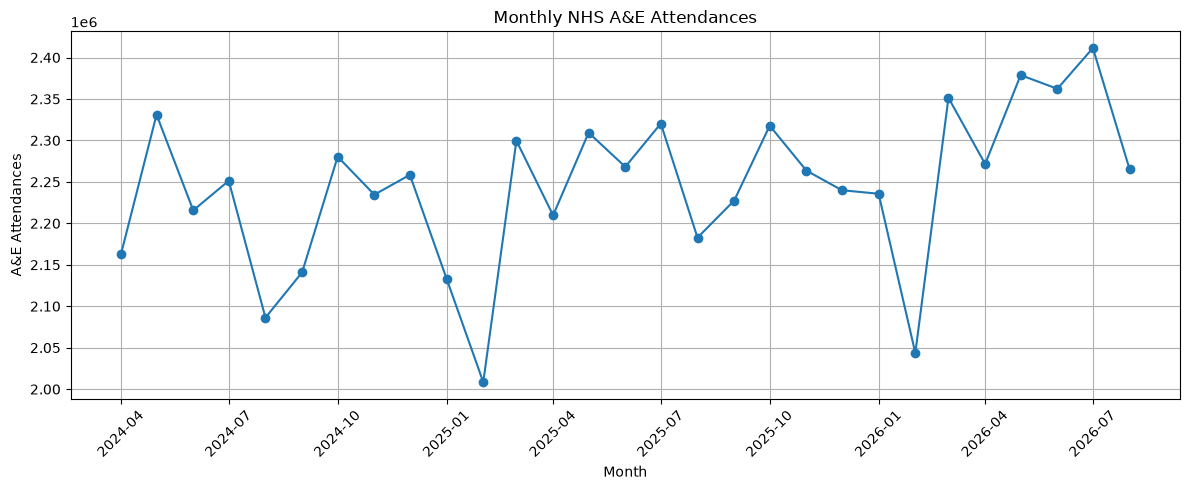

In [72]:
import matplotlib.pyplot as plt

# Plot monthly A&E attendances
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["Attendances"],
    marker="o"
)

# Add chart title and labels
plt.title("Monthly NHS A&E Attendances")
plt.xlabel("Month")
plt.ylabel("A&E Attendances")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [74]:
# Find the month with the highest A&E attendances
highest_month = monthly_df.loc[
    monthly_df["Attendances"].idxmax()
]

# Find the month with the lowest A&E attendances
lowest_month = monthly_df.loc[
    monthly_df["Attendances"].idxmin()
]

print("Highest attendance month:")
print(highest_month[["Month", "Attendances"]])

print("\nLowest attendance month:")
print(lowest_month[["Month", "Attendances"]])

Highest attendance month:
Month          2026-07-01 00:00:00
Attendances                2411415
Name: 27, dtype: object

Lowest attendance month:
Month          2025-02-01 00:00:00
Attendances                2008463
Name: 10, dtype: object


In [75]:
# Get the first and last month's attendance values
first_attendance = monthly_df.iloc[0]["Attendances"]
last_attendance = monthly_df.iloc[-1]["Attendances"]

# Calculate percentage change across the full period
overall_change = (
    (last_attendance - first_attendance)
    / first_attendance
) * 100

print("Overall attendance change:", round(overall_change, 2), "%")

Overall attendance change: 4.72 %


In [76]:
# Calculate the number of days in each month
monthly_df["Days in Month"] = monthly_df["Month"].dt.days_in_month

# Calculate average A&E attendances per day
monthly_df["Attendances per Day"] = (
    monthly_df["Attendances"]
    / monthly_df["Days in Month"]
)

# Show the first 12 months
monthly_df[
    ["Month", "Attendances", "Days in Month", "Attendances per Day"]
].head(12)

,Month,Attendances,Days in Month,Attendances per Day
0,2024-04-01,2163149,30,72104.966667
1,2024-05-01,2331010,31,75193.870968
2,2024-06-01,2215640,30,73854.666667
3,2024-07-01,2251330,31,72623.548387
4,2024-08-01,2086225,31,67297.580645
5,2024-09-01,2140977,30,71365.900000
6,2024-10-01,2280392,31,73561.032258
7,2024-11-01,2234578,30,74485.933333
8,2024-12-01,2258452,31,72853.290323
9,2025-01-01,2133300,31,68816.129032


In [77]:
# Find the month with the lowest average daily attendances
lowest_daily_month = monthly_df.loc[
    monthly_df["Attendances per Day"].idxmin()
]

print(lowest_daily_month[
    ["Month", "Attendances", "Days in Month", "Attendances per Day"]
])

Month                  2024-08-01 00:00:00
Attendances                        2086225
Days in Month                           31
Attendances per Day           67297.580645
Name: 4, dtype: object


In [78]:
# Find the month with the highest average daily attendances
highest_daily_month = monthly_df.loc[
    monthly_df["Attendances per Day"].idxmax()
]

print(
    highest_daily_month[
        ["Month", "Attendances", "Days in Month", "Attendances per Day"]
    ]
)

Month                  2026-06-01 00:00:00
Attendances                        2362271
Days in Month                           30
Attendances per Day           78742.366667
Name: 26, dtype: object


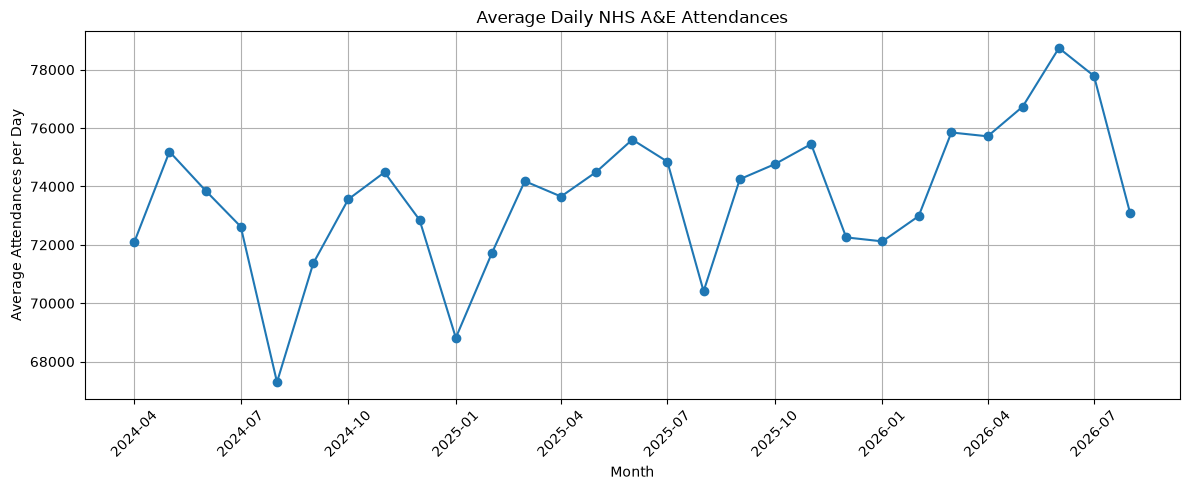

In [79]:
# Plot average daily A&E attendances
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["Attendances per Day"],
    marker="o"
)

# Add chart title and labels
plt.title("Average Daily NHS A&E Attendances")
plt.xlabel("Month")
plt.ylabel("Average Attendances per Day")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

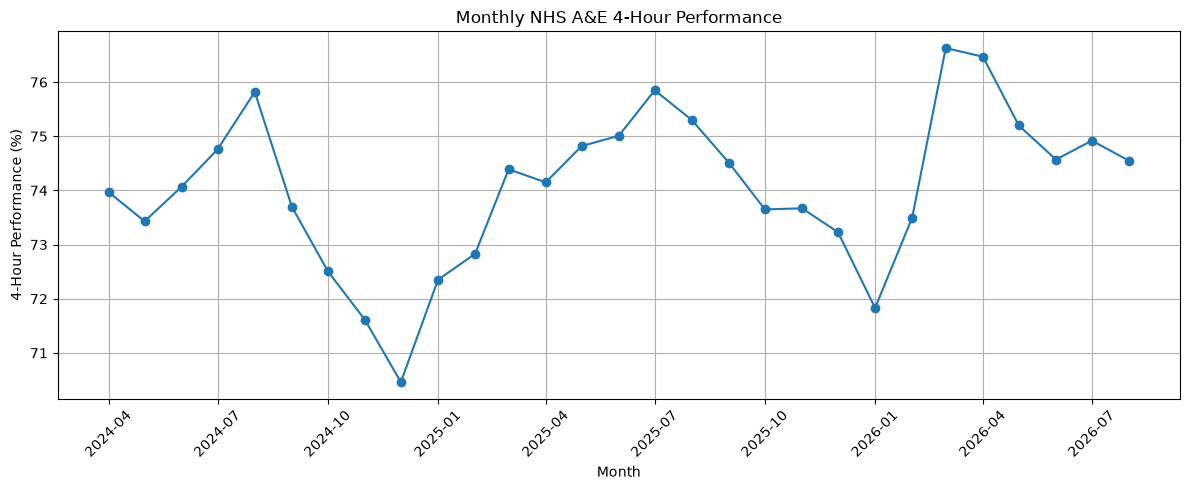

In [80]:
# Plot monthly 4-hour performance
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["4 Hour Performance %"],
    marker="o"
)

# Add chart title and labels
plt.title("Monthly NHS A&E 4-Hour Performance")
plt.xlabel("Month")
plt.ylabel("4-Hour Performance (%)")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [81]:
# Find the best performing month
best_performance = monthly_df.loc[
    monthly_df["4 Hour Performance %"].idxmax()
]

# Find the worst performing month
worst_performance = monthly_df.loc[
    monthly_df["4 Hour Performance %"].idxmin()
]

print("Best performance month:")
print(
    best_performance[
        ["Month", "4 Hour Performance %", "Over 4 Hours"]
    ]
)

print("\nWorst performance month:")
print(
    worst_performance[
        ["Month", "4 Hour Performance %", "Over 4 Hours"]
    ]
)

Best performance month:
Month                   2026-03-01 00:00:00
4 Hour Performance %                  76.63
Over 4 Hours                         549428
Name: 23, dtype: object

Worst performance month:
Month                   2024-12-01 00:00:00
4 Hour Performance %                  70.46
Over 4 Hours                         667235
Name: 8, dtype: object


In [82]:
# Get first and last month's performance
first_performance = monthly_df.iloc[0]["4 Hour Performance %"]
last_performance = monthly_df.iloc[-1]["4 Hour Performance %"]

# Calculate change in percentage points
performance_change = last_performance - first_performance

print("April 2024 performance:", first_performance, "%")
print("August 2026 performance:", last_performance, "%")
print("Change:", round(performance_change, 2), "percentage points")

April 2024 performance: 73.97 %
August 2026 performance: 74.55 %
Change: 0.58 percentage points


In [83]:
# Create a folder for A&E figures
FIGURES_PATH = PROJECT_ROOT / "figures" / "ae"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

print(FIGURES_PATH)

/home/jovyan/work/figures/ae


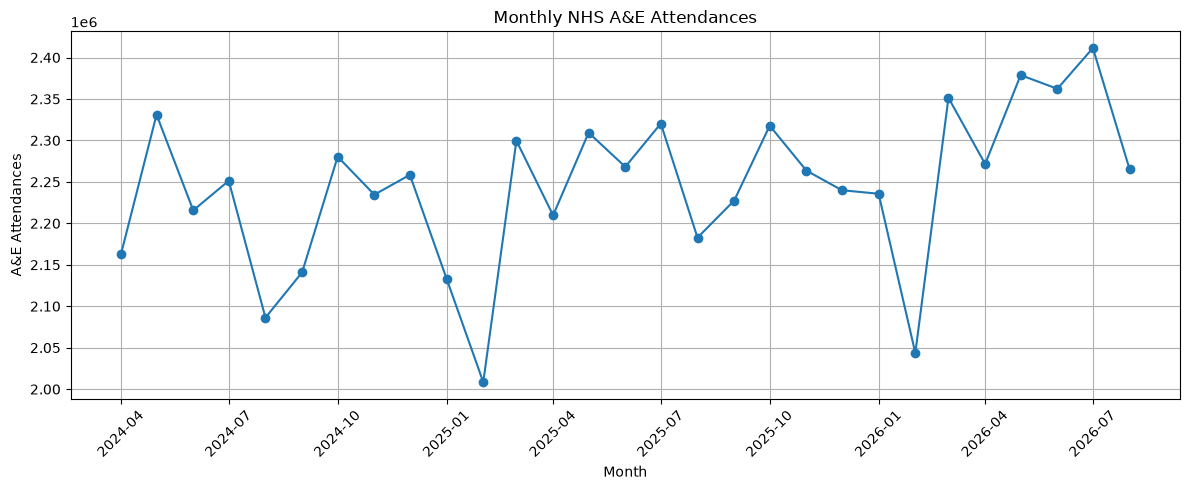

In [84]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["Attendances"],
    marker="o"
)

plt.title("Monthly NHS A&E Attendances")
plt.xlabel("Month")
plt.ylabel("A&E Attendances")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_PATH / "monthly_ae_attendances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

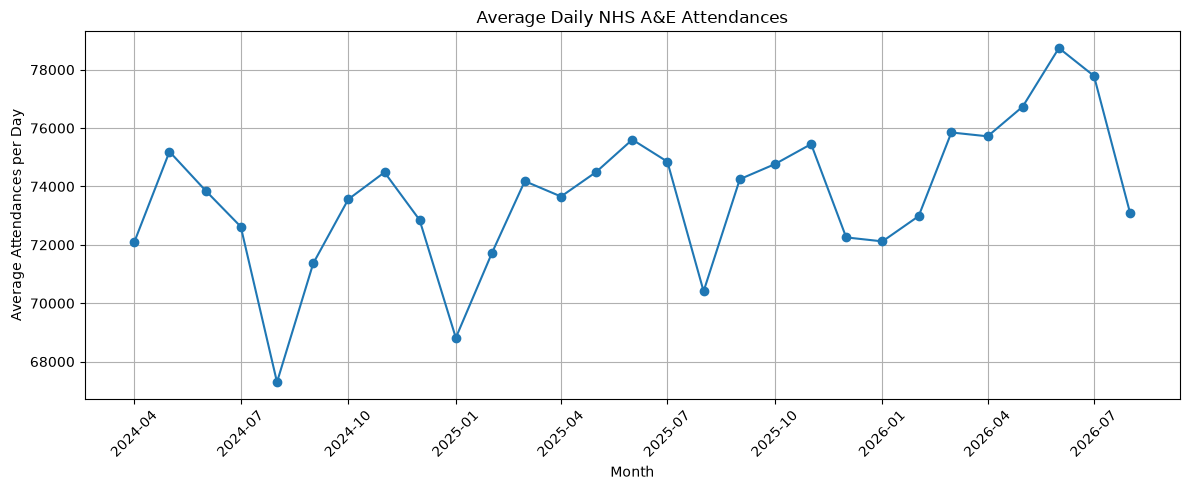

In [88]:
# Create the figure
plt.figure(figsize=(12, 5))

# Plot average daily A&E attendances
plt.plot(
    monthly_df["Month"],
    monthly_df["Attendances per Day"],
    marker="o"
)

# Add title and labels
plt.title("Average Daily NHS A&E Attendances")
plt.xlabel("Month")
plt.ylabel("Average Attendances per Day")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_PATH / "average_daily_ae_attendances.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

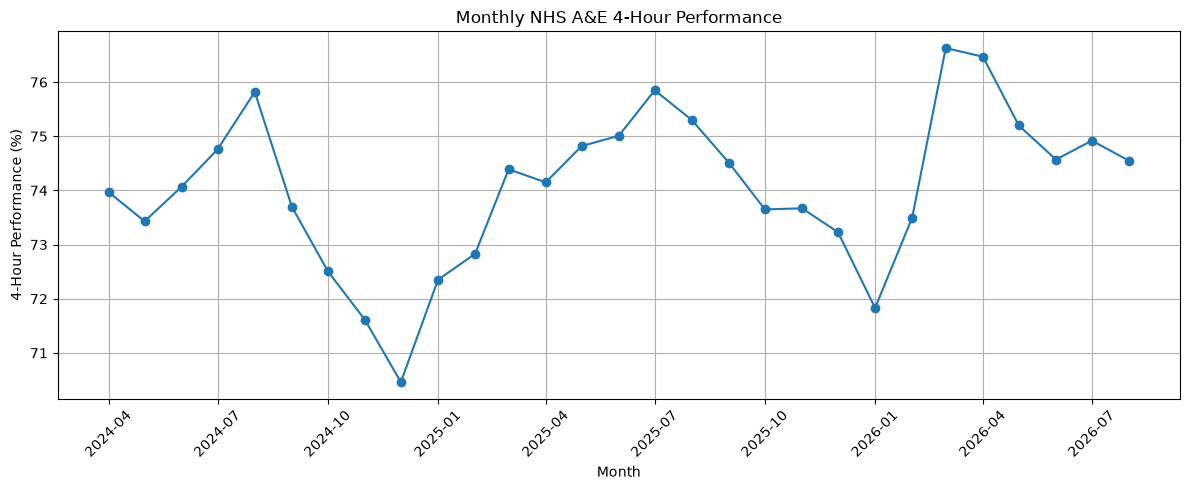

In [89]:
# Create the figure
plt.figure(figsize=(12, 5))

# Plot monthly 4-hour performance
plt.plot(
    monthly_df["Month"],
    monthly_df["4 Hour Performance %"],
    marker="o"
)

# Add title and labels
plt.title("Monthly NHS A&E 4-Hour Performance")
plt.xlabel("Month")
plt.ylabel("4-Hour Performance (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_PATH / "four_hour_performance.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

A&E EMERGENCY ADMISSIONS ANALYSIS

Highest admission rate:
Month                 2025-01-01 00:00:00
Attendances                       2133300
Admissions via A&E                 406228
Admission Rate %                    19.04
Name: 9, dtype: object

Lowest admission rate:
Month                 2026-06-01 00:00:00
Attendances                       2362271
Admissions via A&E                 397954
Admission Rate %                    16.85
Name: 26, dtype: object

Overall change:
First month admission rate: 18.67 %
Last month admission rate: 17.34 %
Change: -1.33 percentage points


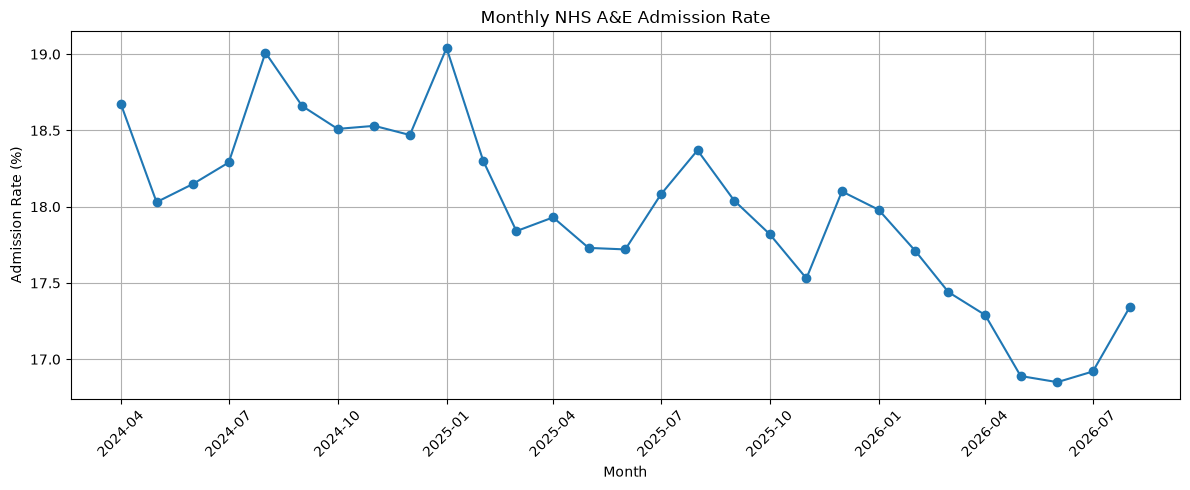


Saved figure:
/home/jovyan/work/figures/ae/ae_admission_rate.png

Saved processed dataset:
/home/jovyan/work/data/processed/ae_monthly_summary.csv

Current dataset shape: (29, 10)


In [91]:
# ============================================================
# A&E EMERGENCY ADMISSIONS ANALYSIS
# ============================================================

# 1. Calculate monthly admission rate
monthly_df["Admission Rate %"] = (
    monthly_df["Admissions via A&E"]
    / monthly_df["Attendances"]
    * 100
).round(2)


# 2. Find the highest and lowest admission rate months
highest_admission = monthly_df.loc[
    monthly_df["Admission Rate %"].idxmax()
]

lowest_admission = monthly_df.loc[
    monthly_df["Admission Rate %"].idxmin()
]


# 3. Calculate change from the first month to the last month
first_admission_rate = monthly_df.iloc[0]["Admission Rate %"]
last_admission_rate = monthly_df.iloc[-1]["Admission Rate %"]

admission_rate_change = (
    last_admission_rate - first_admission_rate
)


# 4. Print analysis summary
print("=" * 55)
print("A&E EMERGENCY ADMISSIONS ANALYSIS")
print("=" * 55)

print("\nHighest admission rate:")
print(
    highest_admission[
        ["Month", "Attendances", "Admissions via A&E", "Admission Rate %"]
    ]
)

print("\nLowest admission rate:")
print(
    lowest_admission[
        ["Month", "Attendances", "Admissions via A&E", "Admission Rate %"]
    ]
)

print("\nOverall change:")
print("First month admission rate:", first_admission_rate, "%")
print("Last month admission rate:", last_admission_rate, "%")
print(
    "Change:",
    round(admission_rate_change, 2),
    "percentage points"
)


# 5. Create admission rate trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["Admission Rate %"],
    marker="o"
)

plt.title("Monthly NHS A&E Admission Rate")
plt.xlabel("Month")
plt.ylabel("Admission Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()


# 6. Save the chart
plt.savefig(
    FIGURES_PATH / "ae_admission_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Create processed data folder
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)


# 8. Save the current monthly analysis dataset
monthly_df.to_csv(
    PROCESSED_PATH / "ae_monthly_summary.csv",
    index=False
)


# 9. Confirm saved outputs
print("\nSaved figure:")
print(FIGURES_PATH / "ae_admission_rate.png")

print("\nSaved processed dataset:")
print(PROCESSED_PATH / "ae_monthly_summary.csv")

print("\nCurrent dataset shape:", monthly_df.shape)

MONTH-ON-MONTH A&E CHANGE ANALYSIS

Biggest attendance increase:
Month                      2026-03-01 00:00:00
Attendances                            2351347
Attendance MoM Change %                  15.06
Name: 23, dtype: object

Biggest attendance decrease:
Month                      2026-02-01 00:00:00
Attendances                            2043572
Attendance MoM Change %                  -8.59
Name: 22, dtype: object

Biggest 4-hour performance improvement:
Month                        2026-03-01 00:00:00
4 Hour Performance %                       76.63
Performance MoM Change pp                   3.13
Name: 23, dtype: object

Biggest 4-hour performance deterioration:
Month                        2024-09-01 00:00:00
4 Hour Performance %                        73.7
Performance MoM Change pp                  -2.12
Name: 5, dtype: object


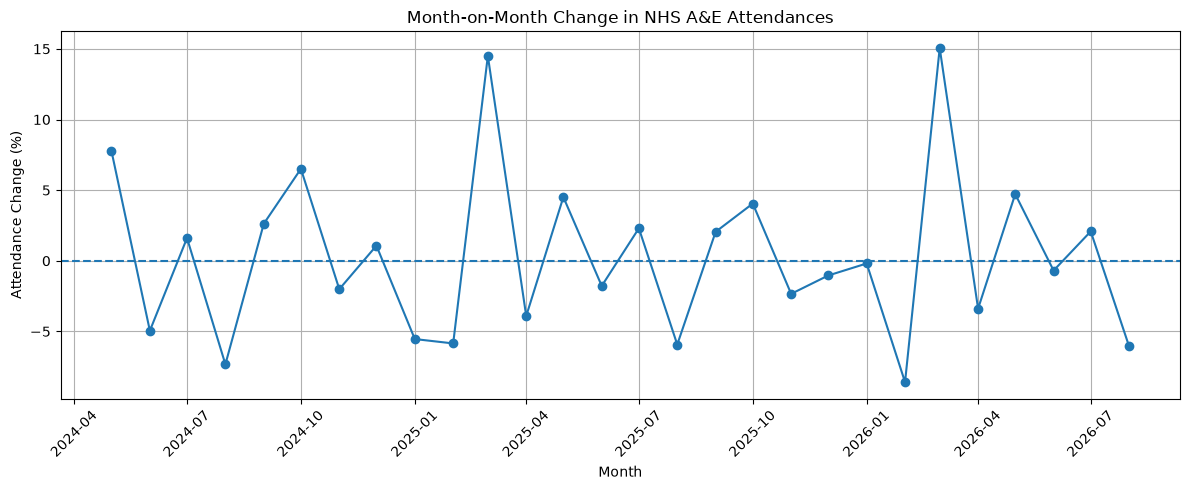

,Month,Attendances,Attendance MoM Change %,4 Hour Performance %,Performance MoM Change pp,Admission Rate %,Admission Rate MoM Change pp
0,2024-04-01,2163149,NaN,73.97,NaN,18.67,NaN
1,2024-05-01,2331010,7.76,73.43,-0.54,18.03,-0.64
2,2024-06-01,2215640,-4.95,74.07,0.64,18.15,0.12
3,2024-07-01,2251330,1.61,74.76,0.69,18.29,0.14
4,2024-08-01,2086225,-7.33,75.82,1.06,19.01,0.72
5,2024-09-01,2140977,2.62,73.70,-2.12,18.66,-0.35
6,2024-10-01,2280392,6.51,72.51,-1.19,18.51,-0.15
7,2024-11-01,2234578,-2.01,71.61,-0.90,18.53,0.02
8,2024-12-01,2258452,1.07,70.46,-1.15,18.47,-0.06
9,2025-01-01,2133300,-5.54,72.35,1.89,19.04,0.57



Updated dataset saved successfully.


In [92]:
# ============================================================
# MONTH-ON-MONTH A&E CHANGE ANALYSIS
# ============================================================

# 1. Calculate month-on-month attendance growth
monthly_df["Attendance MoM Change %"] = (
    monthly_df["Attendances"].pct_change() * 100
).round(2)


# 2. Calculate month-on-month change in 4-hour performance
monthly_df["Performance MoM Change pp"] = (
    monthly_df["4 Hour Performance %"].diff()
).round(2)


# 3. Calculate month-on-month change in admission rate
monthly_df["Admission Rate MoM Change pp"] = (
    monthly_df["Admission Rate %"].diff()
).round(2)


# 4. Find the biggest attendance increase
biggest_attendance_increase = monthly_df.loc[
    monthly_df["Attendance MoM Change %"].idxmax()
]


# 5. Find the biggest attendance decrease
biggest_attendance_decrease = monthly_df.loc[
    monthly_df["Attendance MoM Change %"].idxmin()
]


# 6. Find the biggest performance improvement
biggest_performance_improvement = monthly_df.loc[
    monthly_df["Performance MoM Change pp"].idxmax()
]


# 7. Find the biggest performance deterioration
biggest_performance_drop = monthly_df.loc[
    monthly_df["Performance MoM Change pp"].idxmin()
]


# 8. Print summary
print("=" * 60)
print("MONTH-ON-MONTH A&E CHANGE ANALYSIS")
print("=" * 60)

print("\nBiggest attendance increase:")
print(
    biggest_attendance_increase[
        ["Month", "Attendances", "Attendance MoM Change %"]
    ]
)

print("\nBiggest attendance decrease:")
print(
    biggest_attendance_decrease[
        ["Month", "Attendances", "Attendance MoM Change %"]
    ]
)

print("\nBiggest 4-hour performance improvement:")
print(
    biggest_performance_improvement[
        ["Month", "4 Hour Performance %", "Performance MoM Change pp"]
    ]
)

print("\nBiggest 4-hour performance deterioration:")
print(
    biggest_performance_drop[
        ["Month", "4 Hour Performance %", "Performance MoM Change pp"]
    ]
)


# 9. Create month-on-month attendance change chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month"],
    monthly_df["Attendance MoM Change %"],
    marker="o"
)

# Add a zero reference line
plt.axhline(0, linestyle="--")

plt.title("Month-on-Month Change in NHS A&E Attendances")
plt.xlabel("Month")
plt.ylabel("Attendance Change (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()


# 10. Save the figure
plt.savefig(
    FIGURES_PATH / "ae_month_on_month_attendance_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 11. Save updated processed dataset
monthly_df.to_csv(
    PROCESSED_PATH / "ae_monthly_summary.csv",
    index=False
)


# 12. Show useful columns
display(
    monthly_df[
        [
            "Month",
            "Attendances",
            "Attendance MoM Change %",
            "4 Hour Performance %",
            "Performance MoM Change pp",
            "Admission Rate %",
            "Admission Rate MoM Change pp"
        ]
    ]
)


print("\nUpdated dataset saved successfully.")

PROVIDER-MONTH DATA QUALITY CHECK

Total provider-month rows: 5714
Unique months: 29
Unique organisation codes: 207
Duplicate provider-month rows: 0

Missing calculated values:
Total A&E Attendances      0
Total Over 4 Hours         0
4 Hour Performance %     349
Admissions via A&E         0
Admission Rate %         349
dtype: int64

TOP 10 BUSIEST A&E ORGANISATIONS


,Org name,Months_Reported,Total_Attendances,4 Hour Performance %,Admission Rate %
54,BARTS HEALTH NHS TRUST,29,1280346,71.03,10.01
49,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,29,1155337,71.66,15.07
153,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,29,1115793,63.45,27.63
63,ROYAL FREE LONDON NHS FOUNDATION TRUST,29,1082166,76.95,14.53
88,FRIMLEY HEALTH NHS FOUNDATION TRUST,29,1019373,72.79,17.91
62,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,29,1016100,71.10,25.36
129,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,29,1014573,68.93,21.99
94,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",29,867005,78.49,21.68
150,LEEDS TEACHING HOSPITALS NHS TRUST,29,865253,75.79,12.32
207,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,29,863174,64.22,28.61


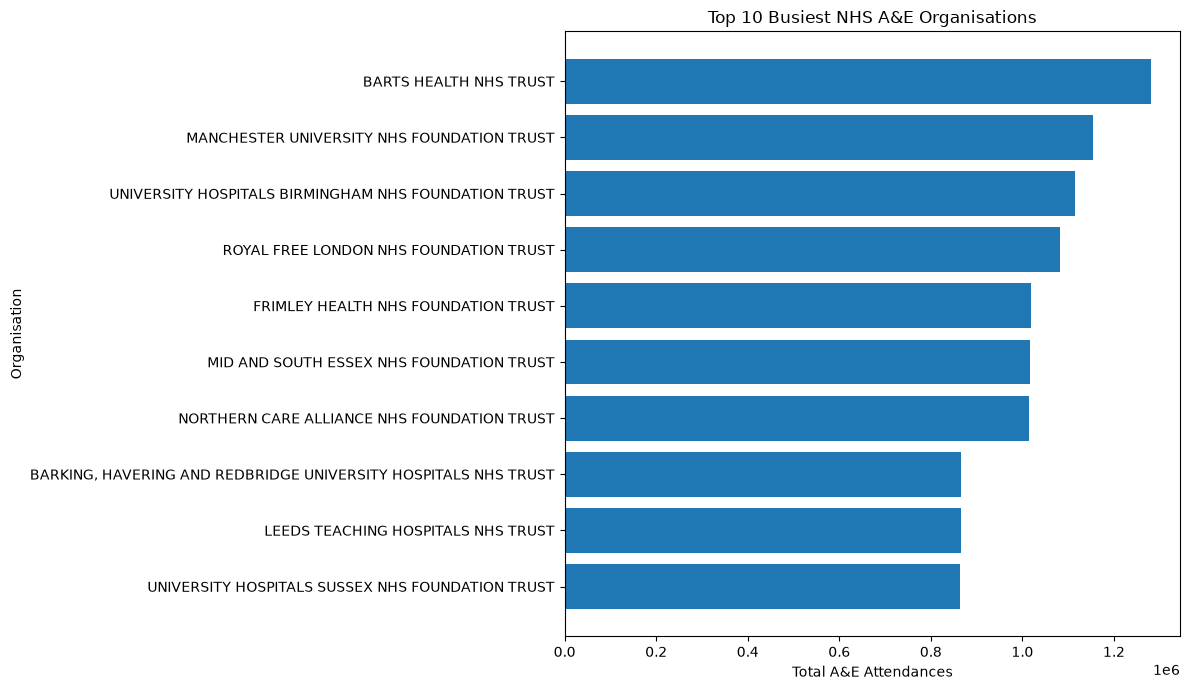


Saved datasets:
/home/jovyan/work/data/processed/ae_provider_month.csv
/home/jovyan/work/data/processed/ae_provider_summary.csv

Saved figure:
/home/jovyan/work/figures/ae/top_10_busiest_ae_organisations.png


In [93]:
# ============================================================
# PROVIDER-LEVEL A&E ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Create a function to process organisation-level data
# ------------------------------------------------------------

def process_ae_provider_file(file_path, month):

    # Load the monthly CSV file
    df = pd.read_csv(file_path)

    # Remove national TOTAL rows
    df_org = df[
        (df["Period"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org Code"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org name"].astype(str).str.strip().str.upper() != "TOTAL")
    ].copy()

    # Add the reporting month
    df_org["Month"] = month

    # Calculate total A&E attendances
    df_org["Total A&E Attendances"] = (
        df_org["A&E attendances Type 1"]
        + df_org["A&E attendances Type 2"]
        + df_org["A&E attendances Other A&E Department"]
    )

    # Calculate total over-4-hour attendances
    df_org["Total Over 4 Hours"] = (
        df_org["Attendances over 4hrs Type 1"]
        + df_org["Attendances over 4hrs Type 2"]
        + df_org["Attendances over 4hrs Other Department"]
    )

    # Calculate 4-hour performance
    df_org["4 Hour Performance %"] = (
        (
            df_org["Total A&E Attendances"]
            - df_org["Total Over 4 Hours"]
        )
        / df_org["Total A&E Attendances"]
        * 100
    ).where(
        df_org["Total A&E Attendances"] > 0
    ).round(2)

    # Calculate admissions through A&E
    df_org["Admissions via A&E"] = (
        df_org["Emergency admissions via A&E - Type 1"]
        + df_org["Emergency admissions via A&E - Type 2"]
        + df_org["Emergency admissions via A&E - Other A&E department"]
    )

    # Calculate admission rate
    df_org["Admission Rate %"] = (
        df_org["Admissions via A&E"]
        / df_org["Total A&E Attendances"]
        * 100
    ).where(
        df_org["Total A&E Attendances"] > 0
    ).round(2)

    # Keep the columns needed for analysis
    return df_org[
        [
            "Month",
            "Org Code",
            "Parent Org",
            "Org name",
            "Total A&E Attendances",
            "Total Over 4 Hours",
            "4 Hour Performance %",
            "Admissions via A&E",
            "Admission Rate %"
        ]
    ]


# ------------------------------------------------------------
# 2. Create a mapping between each file and its month
# ------------------------------------------------------------

file_month_map = (
    monthly_df
    .set_index("File Name")["Month"]
    .to_dict()
)


# ------------------------------------------------------------
# 3. Process all 29 monthly files
# ------------------------------------------------------------

provider_frames = []

for file in ae_files:

    month = file_month_map[file.name]

    provider_data = process_ae_provider_file(
        file,
        month
    )

    provider_frames.append(provider_data)


# Combine all months into one dataset
provider_month_df = pd.concat(
    provider_frames,
    ignore_index=True
)


# ------------------------------------------------------------
# 4. Run data-quality checks
# ------------------------------------------------------------

print("=" * 60)
print("PROVIDER-MONTH DATA QUALITY CHECK")
print("=" * 60)

print(
    "\nTotal provider-month rows:",
    len(provider_month_df)
)

print(
    "Unique months:",
    provider_month_df["Month"].nunique()
)

print(
    "Unique organisation codes:",
    provider_month_df["Org Code"].nunique()
)

# Check duplicate organisation-month combinations
duplicate_provider_months = (
    provider_month_df
    .duplicated(
        subset=["Month", "Org Code"]
    )
    .sum()
)

print(
    "Duplicate provider-month rows:",
    duplicate_provider_months
)

# Check missing values in important calculated columns
print("\nMissing calculated values:")

print(
    provider_month_df[
        [
            "Total A&E Attendances",
            "Total Over 4 Hours",
            "4 Hour Performance %",
            "Admissions via A&E",
            "Admission Rate %"
        ]
    ].isna().sum()
)


# ------------------------------------------------------------
# 5. Save the provider-month dataset
# ------------------------------------------------------------

provider_month_df.to_csv(
    PROCESSED_PATH / "ae_provider_month.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Create provider summary across the full period
# ------------------------------------------------------------

provider_summary = (
    provider_month_df
    .groupby(
        ["Org Code", "Org name"],
        as_index=False
    )
    .agg(
        Months_Reported=(
            "Month",
            "nunique"
        ),
        Total_Attendances=(
            "Total A&E Attendances",
            "sum"
        ),
        Total_Over_4_Hours=(
            "Total Over 4 Hours",
            "sum"
        ),
        Total_Admissions=(
            "Admissions via A&E",
            "sum"
        )
    )
)


# ------------------------------------------------------------
# 7. Calculate full-period provider performance
# ------------------------------------------------------------

# Use weighted totals rather than averaging monthly percentages
provider_summary["4 Hour Performance %"] = (
    (
        provider_summary["Total_Attendances"]
        - provider_summary["Total_Over_4_Hours"]
    )
    / provider_summary["Total_Attendances"]
    * 100
).where(
    provider_summary["Total_Attendances"] > 0
).round(2)


provider_summary["Admission Rate %"] = (
    provider_summary["Total_Admissions"]
    / provider_summary["Total_Attendances"]
    * 100
).where(
    provider_summary["Total_Attendances"] > 0
).round(2)


# ------------------------------------------------------------
# 8. Find the 10 busiest organisations
# ------------------------------------------------------------

top_10_providers = (
    provider_summary
    .sort_values(
        "Total_Attendances",
        ascending=False
    )
    .head(10)
)


print("\n" + "=" * 60)
print("TOP 10 BUSIEST A&E ORGANISATIONS")
print("=" * 60)

display(
    top_10_providers[
        [
            "Org name",
            "Months_Reported",
            "Total_Attendances",
            "4 Hour Performance %",
            "Admission Rate %"
        ]
    ]
)


# ------------------------------------------------------------
# 9. Create top-10 provider chart
# ------------------------------------------------------------

top_10_chart = (
    top_10_providers
    .sort_values(
        "Total_Attendances",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_chart["Org name"],
    top_10_chart["Total_Attendances"]
)

plt.title(
    "Top 10 Busiest NHS A&E Organisations"
)

plt.xlabel(
    "Total A&E Attendances"
)

plt.ylabel(
    "Organisation"
)

plt.tight_layout()


# Save the figure
plt.savefig(
    FIGURES_PATH / "top_10_busiest_ae_organisations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. Save provider summary
# ------------------------------------------------------------

provider_summary.to_csv(
    PROCESSED_PATH / "ae_provider_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 11. Confirm saved outputs
# ------------------------------------------------------------

print("\nSaved datasets:")

print(
    PROCESSED_PATH / "ae_provider_month.csv"
)

print(
    PROCESSED_PATH / "ae_provider_summary.csv"
)

print("\nSaved figure:")

print(
    FIGURES_PATH / "top_10_busiest_ae_organisations.png"
)

MISSING VALUE VALIDATION

Rows with zero A&E attendances: 349
Rows with missing 4-hour performance: 349
Rows with missing admission rate: 349

Are all missing performance values caused by zero attendances? True

PROVIDER ANALYSIS SAMPLE

Providers included: 173

Correlation between average monthly attendances and 4-hour performance:
-0.568

PERFORMANCE BY DEMAND GROUP


,Demand Group,Providers,Average_Monthly_Attendances,Average_4_Hour_Performance
0,Low,44,1803.0,98.23
1,Medium-Low,43,7886.0,75.96
2,Medium-High,43,14420.0,73.33
3,High,43,25425.0,72.79


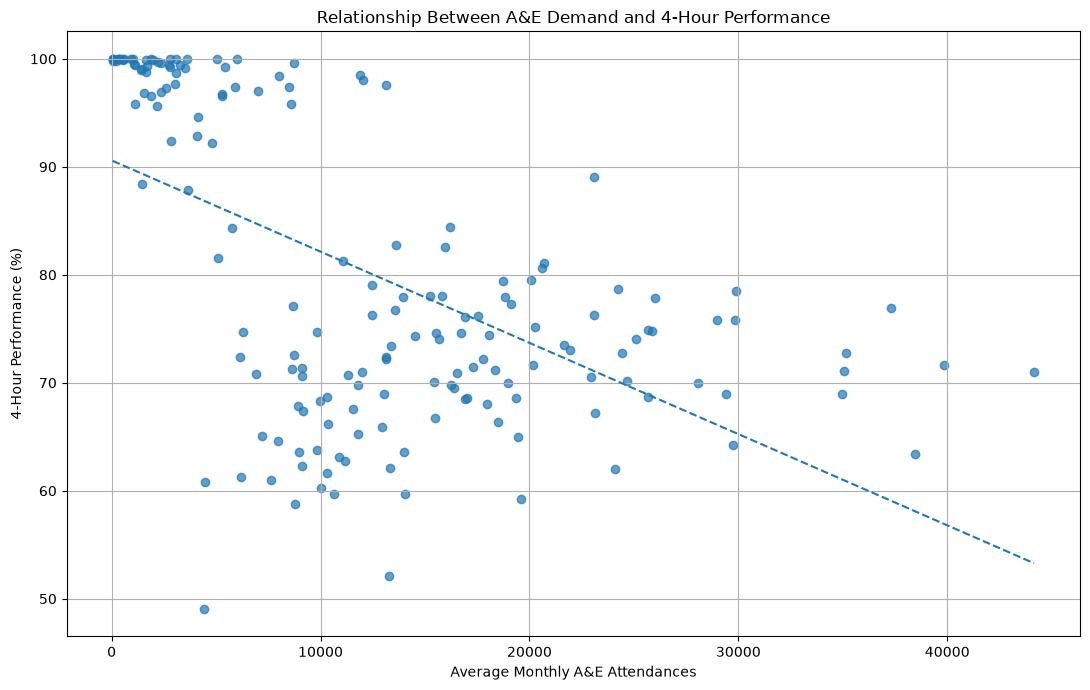


BEST PERFORMING HIGH-VOLUME PROVIDERS


,Org name,Average_Monthly_Attendances,4 Hour Performance %
157,NORTHUMBRIA HEALTHCARE NHS FOUNDATION TRUST,23113.62,89.03
128,NORFOLK AND NORWICH UNIVERSITY HOSPITALS NHS F...,20700.72,81.08
177,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,20582.17,80.59
125,THE ROYAL WOLVERHAMPTON NHS TRUST,20093.97,79.56
137,KETTERING GENERAL HOSPITAL NHS FOUNDATION TRUST,18740.90,79.43



WEAKEST PERFORMING HIGH-VOLUME PROVIDERS


,Org name,Average_Monthly_Attendances,4 Hour Performance %
187,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,19606.90,59.28
176,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,24079.59,61.99
153,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,38475.62,63.45
207,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,29764.62,64.22
182,WORCESTERSHIRE ACUTE HOSPITALS NHS TRUST,19456.59,64.98



Saved figure:
/home/jovyan/work/figures/ae/ae_demand_vs_4hour_performance.png

Provider summary updated successfully.


In [94]:
# ============================================================
# PROVIDER DEMAND VS 4-HOUR PERFORMANCE ANALYSIS
# ============================================================

import numpy as np


# ------------------------------------------------------------
# 1. Investigate missing performance values
# ------------------------------------------------------------

zero_attendance_rows = provider_month_df[
    provider_month_df["Total A&E Attendances"] == 0
]

missing_performance_rows = provider_month_df[
    provider_month_df["4 Hour Performance %"].isna()
]

print("=" * 65)
print("MISSING VALUE VALIDATION")
print("=" * 65)

print(
    "\nRows with zero A&E attendances:",
    len(zero_attendance_rows)
)

print(
    "Rows with missing 4-hour performance:",
    len(missing_performance_rows)
)

print(
    "Rows with missing admission rate:",
    provider_month_df["Admission Rate %"].isna().sum()
)


# Check whether every missing performance row has zero attendances
missing_due_to_zero_activity = (
    missing_performance_rows["Total A&E Attendances"] == 0
).all()

print(
    "\nAre all missing performance values caused by zero attendances?",
    missing_due_to_zero_activity
)


# ------------------------------------------------------------
# 2. Calculate average monthly attendance per provider
# ------------------------------------------------------------

provider_summary["Average_Monthly_Attendances"] = (
    provider_summary["Total_Attendances"]
    / provider_summary["Months_Reported"]
).round(2)


# ------------------------------------------------------------
# 3. Keep providers with meaningful reporting history
# ------------------------------------------------------------

# Providers reporting for at least 24 months are used
# to make the comparison more consistent
analysis_providers = provider_summary[
    (provider_summary["Months_Reported"] >= 24)
    & (provider_summary["Total_Attendances"] > 0)
    & (provider_summary["4 Hour Performance %"].notna())
].copy()


print("\n" + "=" * 65)
print("PROVIDER ANALYSIS SAMPLE")
print("=" * 65)

print(
    "\nProviders included:",
    len(analysis_providers)
)


# ------------------------------------------------------------
# 4. Calculate correlation
# ------------------------------------------------------------

correlation = analysis_providers[
    [
        "Average_Monthly_Attendances",
        "4 Hour Performance %"
    ]
].corr().iloc[0, 1]


print(
    "\nCorrelation between average monthly attendances "
    "and 4-hour performance:"
)

print(
    round(correlation, 3)
)


# ------------------------------------------------------------
# 5. Create simple demand groups
# ------------------------------------------------------------

analysis_providers["Demand Group"] = pd.qcut(
    analysis_providers["Average_Monthly_Attendances"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ]
)


# Calculate average performance for each demand group
demand_group_summary = (
    analysis_providers
    .groupby(
        "Demand Group",
        observed=True
    )
    .agg(
        Providers=(
            "Org Code",
            "count"
        ),
        Average_Monthly_Attendances=(
            "Average_Monthly_Attendances",
            "mean"
        ),
        Average_4_Hour_Performance=(
            "4 Hour Performance %",
            "mean"
        )
    )
    .reset_index()
)


demand_group_summary[
    "Average_Monthly_Attendances"
] = demand_group_summary[
    "Average_Monthly_Attendances"
].round(0)


demand_group_summary[
    "Average_4_Hour_Performance"
] = demand_group_summary[
    "Average_4_Hour_Performance"
].round(2)


print("\n" + "=" * 65)
print("PERFORMANCE BY DEMAND GROUP")
print("=" * 65)

display(demand_group_summary)


# ------------------------------------------------------------
# 6. Create scatter plot
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

plt.scatter(
    analysis_providers["Average_Monthly_Attendances"],
    analysis_providers["4 Hour Performance %"],
    alpha=0.7
)


# ------------------------------------------------------------
# 7. Add a simple trend line
# ------------------------------------------------------------

x = analysis_providers["Average_Monthly_Attendances"]
y = analysis_providers["4 Hour Performance %"]

trend = np.polyfit(x, y, 1)
trend_line = np.poly1d(trend)

plt.plot(
    x.sort_values(),
    trend_line(x.sort_values()),
    linestyle="--"
)


# ------------------------------------------------------------
# 8. Add chart labels
# ------------------------------------------------------------

plt.title(
    "Relationship Between A&E Demand and 4-Hour Performance"
)

plt.xlabel(
    "Average Monthly A&E Attendances"
)

plt.ylabel(
    "4-Hour Performance (%)"
)

plt.grid(True)
plt.tight_layout()


# ------------------------------------------------------------
# 9. Save the figure
# ------------------------------------------------------------

plt.savefig(
    FIGURES_PATH / "ae_demand_vs_4hour_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. Find high-volume providers with strongest
#     and weakest performance
# ------------------------------------------------------------

high_volume_cutoff = analysis_providers[
    "Average_Monthly_Attendances"
].quantile(0.75)

high_volume_providers = analysis_providers[
    analysis_providers[
        "Average_Monthly_Attendances"
    ] >= high_volume_cutoff
].copy()


best_high_volume = (
    high_volume_providers
    .sort_values(
        "4 Hour Performance %",
        ascending=False
    )
    .head(5)
)


worst_high_volume = (
    high_volume_providers
    .sort_values(
        "4 Hour Performance %",
        ascending=True
    )
    .head(5)
)


print("\n" + "=" * 65)
print("BEST PERFORMING HIGH-VOLUME PROVIDERS")
print("=" * 65)

display(
    best_high_volume[
        [
            "Org name",
            "Average_Monthly_Attendances",
            "4 Hour Performance %"
        ]
    ]
)


print("\n" + "=" * 65)
print("WEAKEST PERFORMING HIGH-VOLUME PROVIDERS")
print("=" * 65)

display(
    worst_high_volume[
        [
            "Org name",
            "Average_Monthly_Attendances",
            "4 Hour Performance %"
        ]
    ]
)


# ------------------------------------------------------------
# 11. Save updated provider summary
# ------------------------------------------------------------

provider_summary.to_csv(
    PROCESSED_PATH / "ae_provider_summary.csv",
    index=False
)


print("\nSaved figure:")
print(
    FIGURES_PATH / "ae_demand_vs_4hour_performance.png"
)

print("\nProvider summary updated successfully.")

TYPE 1 A&E PROVIDER ANALYSIS

Providers included: 115

Correlation between Type 1 demand and performance: 0.028

TYPE 1 PERFORMANCE BY DEMAND GROUP


,Demand Group,Providers,Average_Monthly_Attendances,Average_Performance
0,Low,29,6221.0,58.56
1,Medium-Low,29,9242.0,61.95
2,Medium-High,28,12012.0,60.45
3,High,29,18947.0,59.86



BEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS


,Org name,Average Monthly Type 1 Attendances,Type 1 Performance %
177,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,18501.69,78.55
186,CALDERDALE AND HUDDERSFIELD NHS FOUNDATION TRUST,15798.86,78.01
146,CHELSEA AND WESTMINSTER HOSPITAL NHS FOUNDATIO...,19685.62,71.61
62,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,29040.10,65.86
63,ROYAL FREE LONDON NHS FOUNDATION TRUST,23455.97,65.84



WEAKEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS


,Org name,Average Monthly Type 1 Attendances,Type 1 Performance %
187,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,13878.66,46.79
115,UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST,14250.48,48.02
110,LEWISHAM AND GREENWICH NHS TRUST,15196.41,49.52
182,WORCESTERSHIRE ACUTE HOSPITALS NHS TRUST,13587.14,50.28
55,LONDON NORTH WEST UNIVERSITY HEALTHCARE NHS TRUST,13622.31,50.84


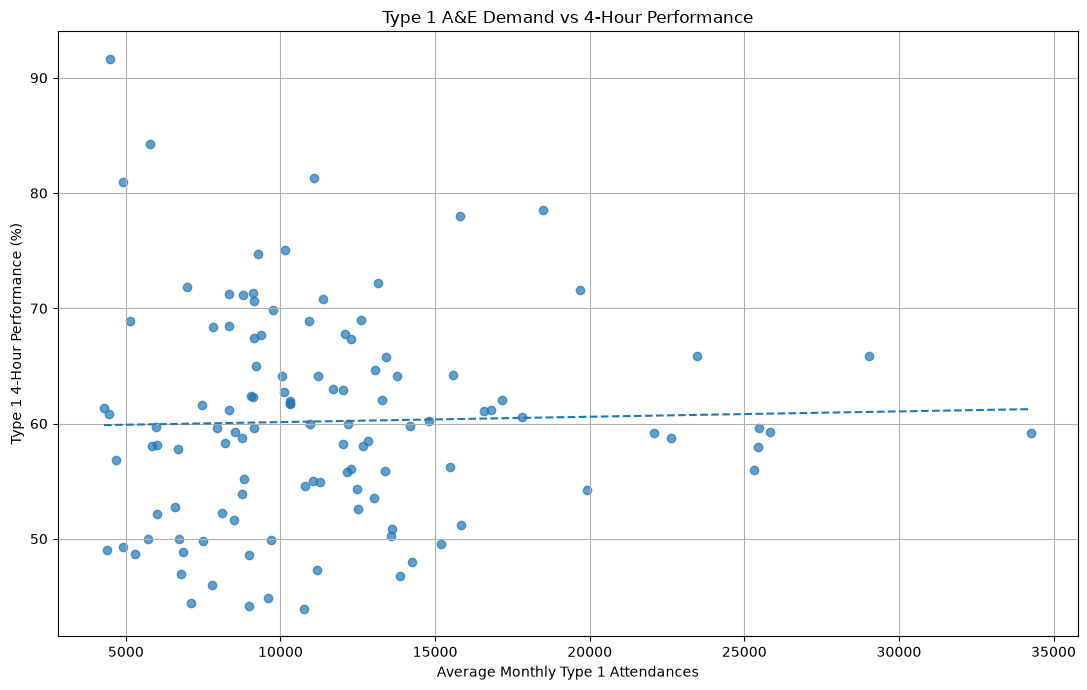


Saved datasets:
/home/jovyan/work/data/processed/ae_type1_provider_month.csv
/home/jovyan/work/data/processed/ae_type1_provider_summary.csv

Saved figure:
/home/jovyan/work/figures/ae/type1_demand_vs_4hour_performance.png


In [95]:
# ============================================================
# TYPE 1 A&E PROVIDER PERFORMANCE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Process Type 1 activity from every monthly file
# ------------------------------------------------------------

type1_frames = []

for file in ae_files:

    # Load monthly file
    df = pd.read_csv(file)

    # Remove national TOTAL row
    df = df[
        (df["Period"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org Code"].astype(str).str.strip().str.upper() != "TOTAL")
        & (df["Org name"].astype(str).str.strip().str.upper() != "TOTAL")
    ].copy()

    # Add reporting month
    df["Month"] = file_month_map[file.name]

    # Keep Type 1 activity
    df["Type 1 Attendances"] = df["A&E attendances Type 1"]
    df["Type 1 Over 4 Hours"] = df["Attendances over 4hrs Type 1"]

    # Calculate Type 1 performance
    df["Type 1 Performance %"] = (
        (
            df["Type 1 Attendances"]
            - df["Type 1 Over 4 Hours"]
        )
        / df["Type 1 Attendances"]
        * 100
    ).where(
        df["Type 1 Attendances"] > 0
    ).round(2)

    type1_frames.append(
        df[
            [
                "Month",
                "Org Code",
                "Org name",
                "Type 1 Attendances",
                "Type 1 Over 4 Hours",
                "Type 1 Performance %"
            ]
        ]
    )


# ------------------------------------------------------------
# 2. Combine all months
# ------------------------------------------------------------

type1_provider_month = pd.concat(
    type1_frames,
    ignore_index=True
)


# ------------------------------------------------------------
# 3. Create full-period provider summary
# ------------------------------------------------------------

type1_summary = (
    type1_provider_month
    .groupby(
        ["Org Code", "Org name"],
        as_index=False
    )
    .agg(
        Months_Reported=("Month", "nunique"),
        Total_Type1_Attendances=("Type 1 Attendances", "sum"),
        Total_Type1_Over4Hours=("Type 1 Over 4 Hours", "sum")
    )
)


# Calculate weighted performance
type1_summary["Type 1 Performance %"] = (
    (
        type1_summary["Total_Type1_Attendances"]
        - type1_summary["Total_Type1_Over4Hours"]
    )
    / type1_summary["Total_Type1_Attendances"]
    * 100
).where(
    type1_summary["Total_Type1_Attendances"] > 0
).round(2)


# Calculate average monthly Type 1 demand
type1_summary["Average Monthly Type 1 Attendances"] = (
    type1_summary["Total_Type1_Attendances"]
    / type1_summary["Months_Reported"]
).round(2)


# ------------------------------------------------------------
# 4. Keep providers with consistent reporting and activity
# ------------------------------------------------------------

type1_analysis = type1_summary[
    (type1_summary["Months_Reported"] >= 24)
    & (type1_summary["Total_Type1_Attendances"] > 0)
    & (type1_summary["Type 1 Performance %"].notna())
].copy()


print("=" * 70)
print("TYPE 1 A&E PROVIDER ANALYSIS")
print("=" * 70)

print("\nProviders included:", len(type1_analysis))


# ------------------------------------------------------------
# 5. Calculate demand-performance correlation
# ------------------------------------------------------------

type1_correlation = type1_analysis[
    [
        "Average Monthly Type 1 Attendances",
        "Type 1 Performance %"
    ]
].corr().iloc[0, 1]

print(
    "\nCorrelation between Type 1 demand and performance:",
    round(type1_correlation, 3)
)


# ------------------------------------------------------------
# 6. Create Type 1 demand quartiles
# ------------------------------------------------------------

type1_analysis["Demand Group"] = pd.qcut(
    type1_analysis["Average Monthly Type 1 Attendances"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ]
)


type1_demand_summary = (
    type1_analysis
    .groupby(
        "Demand Group",
        observed=True
    )
    .agg(
        Providers=("Org Code", "count"),
        Average_Monthly_Attendances=(
            "Average Monthly Type 1 Attendances",
            "mean"
        ),
        Average_Performance=(
            "Type 1 Performance %",
            "mean"
        )
    )
    .reset_index()
)


type1_demand_summary["Average_Monthly_Attendances"] = (
    type1_demand_summary["Average_Monthly_Attendances"]
    .round(0)
)

type1_demand_summary["Average_Performance"] = (
    type1_demand_summary["Average_Performance"]
    .round(2)
)


print("\n" + "=" * 70)
print("TYPE 1 PERFORMANCE BY DEMAND GROUP")
print("=" * 70)

display(type1_demand_summary)


# ------------------------------------------------------------
# 7. Identify high-volume Type 1 providers
# ------------------------------------------------------------

high_volume_cutoff = type1_analysis[
    "Average Monthly Type 1 Attendances"
].quantile(0.75)


high_volume_type1 = type1_analysis[
    type1_analysis["Average Monthly Type 1 Attendances"]
    >= high_volume_cutoff
].copy()


best_high_volume_type1 = (
    high_volume_type1
    .sort_values(
        "Type 1 Performance %",
        ascending=False
    )
    .head(5)
)


worst_high_volume_type1 = (
    high_volume_type1
    .sort_values(
        "Type 1 Performance %",
        ascending=True
    )
    .head(5)
)


print("\n" + "=" * 70)
print("BEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS")
print("=" * 70)

display(
    best_high_volume_type1[
        [
            "Org name",
            "Average Monthly Type 1 Attendances",
            "Type 1 Performance %"
        ]
    ]
)


print("\n" + "=" * 70)
print("WEAKEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS")
print("=" * 70)

display(
    worst_high_volume_type1[
        [
            "Org name",
            "Average Monthly Type 1 Attendances",
            "Type 1 Performance %"
        ]
    ]
)


# ------------------------------------------------------------
# 8. Create scatter plot with trend line
# ------------------------------------------------------------

x = type1_analysis[
    "Average Monthly Type 1 Attendances"
]

y = type1_analysis[
    "Type 1 Performance %"
]


plt.figure(figsize=(11, 7))

plt.scatter(
    x,
    y,
    alpha=0.7
)


# Create trend line
trend = np.polyfit(x, y, 1)
trend_line = np.poly1d(trend)

sorted_x = x.sort_values()

plt.plot(
    sorted_x,
    trend_line(sorted_x),
    linestyle="--"
)


plt.title(
    "Type 1 A&E Demand vs 4-Hour Performance"
)

plt.xlabel(
    "Average Monthly Type 1 Attendances"
)

plt.ylabel(
    "Type 1 4-Hour Performance (%)"
)

plt.grid(True)
plt.tight_layout()


# Save figure
plt.savefig(
    FIGURES_PATH / "type1_demand_vs_4hour_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 9. Save processed datasets
# ------------------------------------------------------------

type1_provider_month.to_csv(
    PROCESSED_PATH / "ae_type1_provider_month.csv",
    index=False
)

type1_summary.to_csv(
    PROCESSED_PATH / "ae_type1_provider_summary.csv",
    index=False
)


print("\nSaved datasets:")
print(PROCESSED_PATH / "ae_type1_provider_month.csv")
print(PROCESSED_PATH / "ae_type1_provider_summary.csv")

print("\nSaved figure:")
print(FIGURES_PATH / "type1_demand_vs_4hour_performance.png")

======================================================================
TYPE 1 A&E PROVIDER ANALYSIS
======================================================================

Providers included: 115

Correlation between Type 1 demand and performance: 0.028

======================================================================
TYPE 1 PERFORMANCE BY DEMAND GROUP
======================================================================
Demand Group	Providers	Average_Monthly_Attendances	Average_Performance
0	Low	29	6221.0	58.56
1	Medium-Low	29	9242.0	61.95
2	Medium-High	28	12012.0	60.45
3	High	29	18947.0	59.86

======================================================================
BEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS
======================================================================
Org name	Average Monthly Type 1 Attendances	Type 1 Performance %
177	MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST	18501.69	78.55
186	CALDERDALE AND HUDDERSFIELD NHS FOUNDATION TRUST	15798.86	78.01
146	CHELSEA AND WESTMINSTER HOSPITAL NHS FOUNDATIO...	19685.62	71.61
62	MID AND SOUTH ESSEX NHS FOUNDATION TRUST	29040.10	65.86
63	ROYAL FREE LONDON NHS FOUNDATION TRUST	23455.97	65.84

======================================================================
WEAKEST PERFORMING HIGH-VOLUME TYPE 1 PROVIDERS
======================================================================
Org name	Average Monthly Type 1 Attendances	Type 1 Performance %
187	NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST	13878.66	46.79
115	UNIVERSITY HOSPITALS OF NORTH MIDLANDS NHS TRUST	14250.48	48.02
110	LEWISHAM AND GREENWICH NHS TRUST	15196.41	49.52
182	WORCESTERSHIRE ACUTE HOSPITALS NHS TRUST	13587.14	50.28
55	LONDON NORTH WEST UNIVERSITY HEALTHCARE NHS TRUST	13622.31	50.84


Saved datasets:
/home/jovyan/work/data/processed/ae_type1_provider_month.csv
/home/jovyan/work/data/processed/ae_type1_provider_summary.csv

Saved figure:
/home/jovyan/work/figures/ae/type1_demand_vs_4hour_performance.png